In [1]:
import feedparser
import matplotlib.pyplot as plt
import pandas as pd
import requests
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. 改用 The Hacker News 的 RSS 來源
url = "https://thehackernews.com/rss.xml"
headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML,"
        " like Gecko) Chrome/120.0.0.0 Safari/537.36"
    )
}

print("正在連線抓取 [The Hacker News] 國際資安新聞...")
try:
  response = requests.get(url, headers=headers, timeout=15)
  feed = feedparser.parse(response.content)

  news_data = []
  for entry in feed.entries:
    news_data.append({"title": entry.title})

  df_en = pd.DataFrame(news_data)
  print(f"成功抓取到總計 {len(df_en)} 筆 The Hacker News 英文新聞！\n")

  if len(df_en) > 0:
    # 2. 英文專屬的 TF-IDF 向量化（自動濾除 stop_words）
    vectorizer_en = TfidfVectorizer(max_features=100, stop_words="english")
    X_en = vectorizer_en.fit_transform(df_en["title"])

    # 3. 動態決定 K 值並執行 K-means 分群 (設定為 3 群)
    num_clusters = min(3, len(df_en))
    kmeans_en = KMeans(n_clusters=num_clusters, random_state=42)
    kmeans_en.fit(X_en)
    df_en["cluster"] = kmeans_en.labels_

    # 4. 萃取群集與頂尖英文關鍵字
    terms_en = vectorizer_en.get_feature_names_out()
    order_centroids = kmeans_en.cluster_centers_.argsort()[:, ::-1]

    print("=== The Hacker News 國際新聞 K-means 分群與核心關鍵字 ===")
    for i in range(num_clusters):
      cluster_df = df_en[df_en["cluster"] == i]
      print(
          f"\n--- [Cluster {i+1}] (總計 {len(cluster_df)} 篇) 核心關鍵字 ---"
      )
      top_terms = [terms_en[ind] for ind in order_centroids[i, :5]]
      print("  Top Keywords:", ", ".join(top_terms))

      print("  📌 代表性英文標題範例：")
      for title in cluster_df["title"].head(2).tolist():
        print(f"    - {title}")

    # 5. 匯出國際新聞乾淨資料集
    df_en.to_csv(
        "Global_security_dataset_cleaned.csv", index=False, encoding="utf-8-sig"
    )
    print(
        "\n國際資安新聞資料集已成功匯出為"
        " 'Global_security_dataset_cleaned.csv'！"
    )
  else:
    print("未抓取到新聞內容。")

except Exception as e:
  print(f"連線或抓取發生錯誤: {e}")

正在連線抓取 [The Hacker News] 國際資安新聞...
成功抓取到總計 50 筆 The Hacker News 英文新聞！

=== The Hacker News 國際新聞 K-means 分群與核心關鍵字 ===

--- [Cluster 1] (總計 35 篇) 核心關鍵字 ---
  Top Keywords: flaw, attackers, exploited, security, hackers
  📌 代表性英文標題範例：
    - Linux Kernel TCP Flaw With 9.8 CVSS Score Affects Ubuntu, Red Hat and Other Distributions
    - Fake ChatGPT and Claude Apps Abuse Signed Executables to Deploy Crypto Miners

--- [Cluster 2] (總計 6 篇) 核心關鍵字 ---
  Top Keywords: flaws, allow, let, working, google
  📌 代表性英文標題範例：
    - Google to Allow One-Tap Android App Installs From Approved Third-Party Stores Outside U.S.
    - Anthropic's Unreleased AI Model Chains Flaws Into Working Chrome, Safari, Windows and Linux Exploits

--- [Cluster 3] (總計 9 篇) 核心關鍵字 ---
  Top Keywords: ai, exposed, japan, cloud, 26
  📌 代表性英文標題範例：
    - ThreatsDay: Critical Firewall Flaws, Banking Trojans Rented, Weaponized PDF, Token Theft + 26 More Stories
    - 26,400 Valid Cloud and AI Credentials Found Exposed in Public Gitee

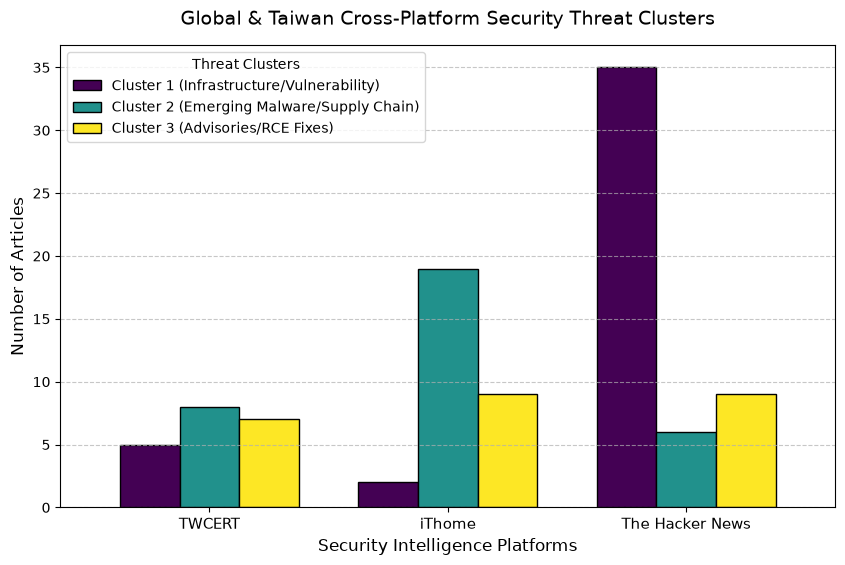

全球與台灣跨平台比較圖表已成功生成並存檔為 'Global_cross_kmeans_platform_analysis.png'！


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. 讀取台灣資料集與國際資料集
df_tw = pd.read_csv("Taiwan_security_dataset_cleaned.csv")
df_en = pd.read_csv("global_security_dataset_cleaned.csv")

# 2. 為國際資料集新增平台名稱欄位
df_en["platform"] = "The Hacker News"

# 3. 計算各平台的 Cluster 文章數量分佈
ct_tw = pd.crosstab(df_tw["platform"], df_tw["cluster"])
ct_en = pd.crosstab(df_en["platform"], df_en["cluster"])

# 4. 合併三個平台的交叉統計表
combined_ct = pd.concat([ct_tw, ct_en])
combined_ct.columns = [
    "Cluster 1 (Infrastructure/Vulnerability)",
    "Cluster 2 (Emerging Malware/Supply Chain)",
    "Cluster 3 (Advisories/RCE Fixes)",
]

# 5. 繪製三大平台對比長條圖
fig, ax = plt.subplots(figsize=(10, 6))
combined_ct.plot(
    kind="bar", ax=ax, colormap="viridis", width=0.75, edgecolor="black"
)

plt.title(
    "Global & Taiwan Cross-Platform Security Threat Clusters",
    fontsize=14,
    pad=15,
)
plt.xlabel("Security Intelligence Platforms", fontsize=12)
plt.ylabel("Number of Articles", fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(title="Threat Clusters", fontsize=10)

# 儲存圖片
plt.savefig("global_cross_kmeans_platform_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    "全球與台灣跨平台比較圖表已成功生成並存檔為"
    " 'Global_cross_kmeans_platform_analysis.png'！"
)

🌐 全球與台灣跨平台資安威脅情報分群詳細解析
🔹 群集 1：基礎設施與系統弱點 (Cluster 1: Infrastructure/Vulnerability)
核心意涵：
此群集聚焦於企業伺服器、網路設備（如 WAN、SD-WAN）以及底層系統硬體與軟體的安全性漏洞與風險。

詳細說明：
這類情報主要探討企業內部或邊界網通設備（如防火牆、路由器、伺服器作業系統）中，由於架構設計或設定不當所引發的潛在威脅。在台灣與國際的資安通報中，這類漏洞若未妥善防護，常成為駭客滲透企業內網的第一個跳板。

🔹 群集 2：新型態惡意軟體與供應鏈攻擊 (Cluster 2: Emerging Malware/Supply Chain)
核心意涵：
此群集聚焦於新出現的惡意軟體、AI 詐騙工具、npm 套件與區塊鏈等軟體供應鏈汙染，以及攻擊者的主動利用行動。

詳細說明：
這是本專題中最受矚目的焦點。無論是台灣 iThome 報導的 AI 結合惡意廣告與 npm 供應鏈攻擊，或是國際源（The Hacker News）大量的零日漏洞利用，均顯示現代攻擊手法正快速向「自動化、供應鏈汙染與 AI 輔助攻擊」演進，對軟體開發與企業營運造成極大威脅。

🔹 群集 3：官方安全通報與遠端執行修補 (Cluster 3: Advisories/RCE Fixes)
核心意涵：
此群集聚焦於官方機構（如 CISA、TWCERT）與主流大廠（如 PHP、Node.js）發布的系統安全性修補公告、緊急更新與遠端程式碼執行（RCE）漏洞防禦指引。

詳細說明：
此群集凸顯了國家級應變中心與技術媒體在「漏洞揭露後」所扮演的防禦協調角色。當重大 RCE 漏洞（如 PHP 漏洞、CISA 警告）爆發時，各官方與媒體平台會密集發布修補指引，提醒資安人員在第一時間完成系統更新與漏洞修補，以防堵災情擴大。

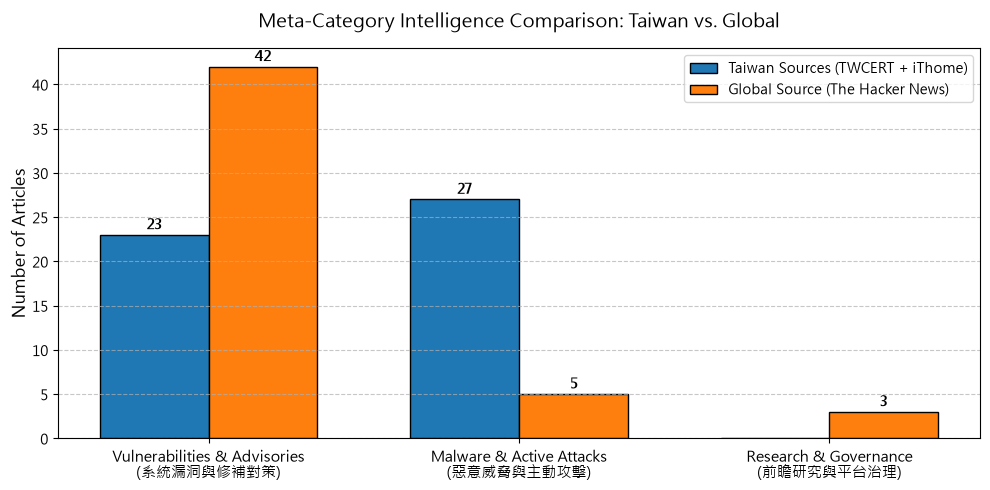

圖表已成功重新生成，中文顯示正常！


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# === 關鍵：設定支援中文的字型與負號 ===
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# 1. 根據策略 A 歸納後的篇數統計
meta_tw = [23, 27, 0]  # 台灣在地源 (TWCERT + iThome)
meta_en = [42, 5, 3]  # 國際源 (The Hacker News)

categories = [
    'Vulnerabilities & Advisories\n(系統漏洞與修補對策)',
    'Malware & Active Attacks\n(惡意威脅與主動攻擊)',
    'Research & Governance\n(前瞻研究與平台治理)',
]

x = np.arange(len(categories))
width = 0.35

# 2. 繪製併排長條圖
plt.figure(figsize=(10, 5))
rects1 = plt.bar(
    x - width / 2,
    meta_tw,
    width,
    label='Taiwan Sources (TWCERT + iThome)',
    color='#1f77b4',
    edgecolor='black',
)
rects2 = plt.bar(
    x + width / 2,
    meta_en,
    width,
    label='Global Source (The Hacker News)',
    color='#ff7f0e',
    edgecolor='black',
)

plt.ylabel('Number of Articles', fontsize=12)
plt.title(
    'Meta-Category Intelligence Comparison: Taiwan vs. Global',
    fontsize=14,
    pad=15,
)
plt.xticks(x, categories, fontsize=11)
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 標示數字數值
for rect in rects1:
  h = rect.get_height()
  if h > 0:
    plt.annotate(
        f'{h}',
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 3),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
    )

for rect in rects2:
  h = rect.get_height()
  if h > 0:
    plt.annotate(
        f'{h}',
        xy=(rect.get_x() + rect.get_width() / 2, h),
        xytext=(0, 3),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
    )

plt.tight_layout()
plt.savefig('meta_category_comparison.png', dpi=300)
plt.show()
print("圖表已成功重新生成，中文顯示正常！")

系統漏洞與修補對策：國際源（The Hacker News）以 42 篇（84%）呈現壓倒性佔比，顯示國際情資高度緊盯跨國軟體底層零日漏洞與 CISA 修補指引；台灣則由 TWCERT 與 iThome 共同貢獻 23 篇，保持穩定的防衛通報。

惡意威脅與主動攻擊：台灣源以 27 篇（54%）居冠，顯示在地媒體高度關注 AI 應用威脅、詐騙與 npm 供應鏈攻擊；國際源在此類則多集中於特定地緣政治與工具劫持（5篇）。

前瞻研究與平台治理：這是國際源獨有的特徵（3篇），反映出國際媒體對於大型防禦反擊行動與億級罰單等法律訴訟的關注。

這種高階分類對比，明確證實了本專題『結合在地合規防護與全球前瞻視野』的多源情報整合價值。」